# 2024 — Kolmogorov–Arnold Networks (KAN)

**Paper:** Ziming Liu et al., *"KAN: Kolmogorov–Arnold Networks"* (2024).

An MLP puts **fixed** nonlinearities on **nodes** and learnable linear weights on edges. A KAN does the reverse: every **edge** carries a **learnable 1-D function** $\phi_{j,i}$ (a B-spline), and nodes just add:

$$x^{(l+1)}_j = \sum_i \phi^{(l)}_{j,i}\big(x^{(l)}_i\big), \qquad \phi(x) = w_b\,\operatorname{SiLU}(x) + w_s \sum_c c_c B_c(x)$$

The motivation is the **Kolmogorov–Arnold representation theorem**: any continuous multivariate function is a sum of compositions of univariate functions. KANs can be very parameter-efficient on smooth "scientific" functions, and the learned edge functions can be plotted and even matched to symbolic formulas. Whether they beat MLPs in general is still debated. They are slower, and on standard ML tasks often no better.

Below: a B-spline KAN from scratch, fitted to $f(x,y) = \exp(\sin(\pi x) + y^2)$ from the paper, and compared to an MLP.

![Diagram: Kolmogorov–Arnold network (Liu et al., 2024)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/66_2024_kan.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class KANLayer(nn.Module):
    def __init__(self, n_in, n_out, grid_size=5, k=3, grid_range=(-1, 1)):
        super().__init__()
        self.k = k
        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = torch.arange(-k, grid_size + k + 1) * h + grid_range[0]                    # extended knot vector
        self.register_buffer("grid", grid.expand(n_in, -1).contiguous())                    # (in, G + 2k + 1)
        self.coef = nn.Parameter(torch.randn(n_out, n_in, grid_size + k) * 0.1)             # spline coefficients
        self.w_base = nn.Parameter(torch.randn(n_out, n_in) / math.sqrt(n_in))              # residual SiLU path
        self.w_spline = nn.Parameter(torch.ones(n_out, n_in))

    def b_splines(self, x):
        """Cox–de Boor recursion. x: (B, in) -> (B, in, G + k) basis values."""
        g = self.grid; x = x.unsqueeze(-1)
        B = ((x >= g[:, :-1]) & (x < g[:, 1:])).to(x.dtype)
        for p in range(1, self.k + 1):
            B = (x - g[:, :-(p + 1)]) / (g[:, p:-1] - g[:, :-(p + 1)]) * B[..., :-1] + \
                (g[:, p + 1:] - x) / (g[:, p + 1:] - g[:, 1:-p]) * B[..., 1:]
        return B

    def phi(self, x):
        """All edge functions evaluated: (B, out, in)."""
        spline = torch.einsum("bic,oic->boi", self.b_splines(x), self.coef)
        return self.w_base * F.silu(x).unsqueeze(1) + self.w_spline * spline

    def forward(self, x):
        return self.phi(x).sum(-1)                                                           # nodes just sum

class KAN(nn.Module):
    def __init__(self, widths, grid_size=5):
        super().__init__()
        self.layers = nn.ModuleList([KANLayer(a, b, grid_size, grid_range=(-1, 1) if i == 0 else (-2, 2))
                                     for i, (a, b) in enumerate(zip(widths[:-1], widths[1:]))])
    def forward(self, x):
        for l in self.layers: x = l(x)
        return x

In [3]:
f = lambda X: torch.exp(torch.sin(math.pi * X[:, :1]) + X[:, 1:] ** 2)
Xtr = torch.rand(1000, 2, device=device) * 2 - 1; Ytr = f(Xtr)
Xte = torch.rand(1000, 2, device=device) * 2 - 1; Yte = f(Xte)

def fit(model, steps=3000, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        loss = F.mse_loss(model(Xtr), Ytr); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    with torch.no_grad(): return F.mse_loss(model(Xte), Yte).sqrt().item()

n_params = lambda m: sum(p.numel() for p in m.parameters())
results = []
for name, mk, lr in [("KAN [2,5,1], grid 5", lambda: KAN([2, 5, 1], 5), 1e-2),
                     ("KAN [2,1,1], grid 5", lambda: KAN([2, 1, 1], 5), 3e-2),
                     ("MLP [2,32,1]", lambda: nn.Sequential(nn.Linear(2, 32), nn.SiLU(), nn.Linear(32, 1)), 1e-2),
                     ("MLP [2,64,64,1]", lambda: nn.Sequential(nn.Linear(2, 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 1)), 3e-3)]:
    seed_everything(0); m = mk().to(device)
    rmse = fit(m, steps=5000, lr=lr); results.append((name, n_params(m), rmse, m))
    print(f"{name:22s} params {n_params(m):6,d}   test RMSE {rmse:.4f}")

KAN [2,5,1], grid 5    params    150   test RMSE 0.0042


KAN [2,1,1], grid 5    params     30   test RMSE 0.0068


MLP [2,32,1]           params    129   test RMSE 0.1349


MLP [2,64,64,1]        params  4,417   test RMSE 0.0165


## Interpretability: plot the learned edge functions
The `[2,1,1]` KAN matches the formula's structure, $f = \exp(\,g_1(x) + g_2(y)\,)$. Its first-layer edges should look like $\sin(\pi x)$ and $y^2$ (up to scale and shift), and the second-layer edge like $\exp$.

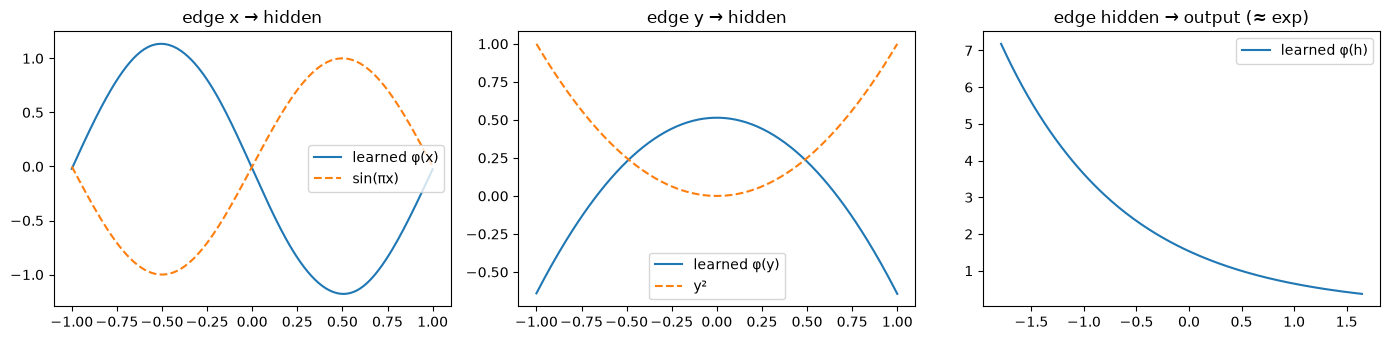

In [4]:
kan = results[1][3]
xs = torch.linspace(-1, 1, 200, device=device)[:, None].repeat(1, 2)
with torch.no_grad():
    phi1 = kan.layers[0].phi(xs)[:, 0].cpu()                               # (200, in=2) edges into the hidden node
    hid = kan.layers[0](torch.rand(2000, 2, device=device) * 2 - 1)
    hs = torch.linspace(hid.min().item(), hid.max().item(), 200, device=device)[:, None]
    phi2 = kan.layers[1].phi(hs)[:, 0, 0].cpu()
x = xs[:, 0].cpu()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(x, phi1[:, 0], label="learned φ(x)"); axes[0].plot(x, torch.sin(math.pi * x), "--", label="sin(πx)"); axes[0].set_title("edge x → hidden")
axes[1].plot(x, phi1[:, 1], label="learned φ(y)"); axes[1].plot(x, x ** 2, "--", label="y²"); axes[1].set_title("edge y → hidden")
axes[2].plot(hs.cpu(), phi2, label="learned φ(h)"); axes[2].set_title("edge hidden → output (≈ exp)")
for a in axes: a.legend()
plt.tight_layout(); plt.show()